In [69]:
import matplotlib
import matplotlib.pyplot as plt
from matplotlib import rc
import numpy as np
from matplotlib import colors

Funkcje do zaimplementowania:

In [ ]:
# konwerter: nie trzeba implementować samemu, można wykorzystać gotową funkcję z biblioteki
def hsv2rgb(h, s, v):
    r, g, b = colors.hsv_to_rgb([h, s, v])
    return (r, g, b)

# poniżej znajdują się funkcje modelujące kolejne gradienty z zadania.
# v to pozycja na osi ox: v jest od 0 do 1. Zewnetrzna funkcja wywołuje te metody
# podając różne v i oczekując trójki RGB bądź HSV reprezentującej kolor
# np. (0,0,0) w RGB to kolor czarny.
# Należy uwikłać v w funkcję modelująca kolor. W tym celu dla kolejnych gradientów
# trzeba przyjąć sobie jakieś punkty charakterystyczne,
# np. widzimy, że po lewej stronie (dla v=0) powinien być kolor zielony,
# a w środku niebieski (dla v = 0.5), a wszystkie punkty pomiędzy
# należy interpolować liniowo (proporcjonalnie).


def gradient_rgb_bw(v):
    return (v, v, v)


def gradient_rgb_gbr(v):
    if v <= 0.5:
        # zielony -> niebieski
        t = v * 2
        r = 0.0
        g = 1.0 - t
        b = t
    else:
        # niebieski -> czerwony
        t = (v - 0.5) * 2
        r = t
        g = 0.0
        b = 1.0 - t
    return (r, g, b)


def gradient_rgb_gbr_full(v):
    if v < 0.25:
        # zieloney -> cyjan
        r = 0.0
        g = 1.0
        b = v * 4
    elif v < 0.5:
        # cyjan -> niebieski
        r = 0.0
        g = 1.0 - (v - 0.25) * 4
        b = 1.0
    elif v < 0.75:
        # niebieski -> magenta
        r = (v - 0.5) * 4
        g = 0.0
        b = 1.0
    else:
        # magenta -> czerwony
        r = 1.0
        g = 0.0
        b = 1.0 - (v - 0.75) * 4
    return (r, g, b)


def gradient_rgb_wb_custom(v):
    if v < 1/7:
        # bialy -> fioletowy
        r = 1.0
        g = 1.0 - v * 7
        b = 1.0
    elif v < 2/7:
        # fioletowy -> niebieski
        r = 1.0 - (v - 1/7) * 7
        g = 0.0
        b = 1.0
    elif v < 3/7:
        # niebieski -> cyjan
        r = 0.0
        g = (v - 2/7) * 7
        b = 1.0
    elif v < 4/7:
        # cyjan -> zielony
        r = 0.0
        g = 1.0
        b = 1.0 - (v - 3/7) * 7
    elif v < 5/7:
        # zielony -> zolty
        r = (v - 4/7) * 7
        g = 1.0
        b = 0.0
    elif v < 6/7:
        # zolty -> czerwony
        r = 1.0
        g = 1.0 - (v - 5/7) * 7
        b = 0.0
    else:
        # czerwony -> czarny
        r = 1.0 - (v - 6/7) * 7
        g = 0.0
        b = 0.0
    return (r, g, b)


def gradient_hsv_bw(v):
    h = 0.0
    s = 0.0
    val = v
    return hsv2rgb(h, s, val)


def gradient_hsv_gbr(v):
    h = 1/3 + v * (2/3)
    s = 1.0
    val = 1.0
    return hsv2rgb(h, s, val)

def gradient_hsv_unknown(v):
    h = 1/3 - v * (1/3)
    s = 0.5
    val = 1.0
    return hsv2rgb(h, s, val)


def gradient_hsv_custom(v):
    if v < 1/3:
        # granatowy -> bordowy
        t = v * 3
        h = 0.66 + t * (0.95 - 0.66)
        s = 1.0
        val = 0.5 + t * (0.6 - 0.5)
    elif v < 2/3:
        # bordowy -> zolty
        t = (v - 1/3) * 3
        h = 0.95 + t * (1.15 - 0.95)
        s = 1.0
        val = 0.6 + t * (1.0 - 0.6)
    else:
        # zolty -> bialy
        t = (v - 2/3) * 3
        h = 0.15
        s = 1.0 - t
        val = 1.0
        # miały to być kolory fc barcelony wydaje mi się, ze ciekawe :)
    return hsv2rgb(h, s, val)

In [71]:
def plot_color_gradients(gradients, names):
    # For pretty latex fonts (commented out, because it does not work on some machines)
    #rc('text', usetex=True)
    #rc('font', family='serif', serif=['Times'], size=10)
    rc('legend', fontsize=10)

    column_width_pt = 400         # Show in latex using \the\linewidth
    pt_per_inch = 72
    size = column_width_pt / pt_per_inch

    fig, axes = plt.subplots(nrows=len(gradients), sharex=True, figsize=(size, 0.75 * size))
    fig.subplots_adjust(top=1.00, bottom=0.05, left=0.25, right=0.95)


    for ax, gradient, name in zip(axes, gradients, names):
        # Create image with two lines and draw gradient on it
        img = np.zeros((2, 1024, 3))
        for i, v in enumerate(np.linspace(0, 1, 1024)):
            img[:, i] = gradient(v)

        im = ax.imshow(img, aspect='auto')
        im.set_extent([0, 1, 0, 1])
        ax.yaxis.set_visible(False)

        pos = list(ax.get_position().bounds)
        x_text = pos[0] - 0.25
        y_text = pos[1] + pos[3]/2.
        fig.text(x_text, y_text, name, va='center', ha='left', fontsize=10)

    fig.savefig('my-gradients.pdf')

Clipping input data to the valid range for imshow with RGB data ([0..1] for floats or [0..255] for integers). Got range [-4.440892098500626e-16..1.0].


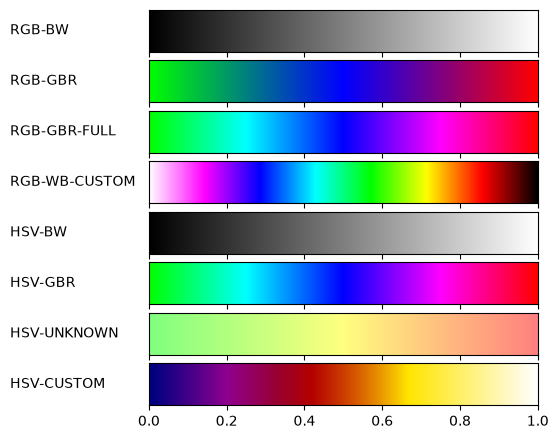

In [72]:
def toname(g):
    return g.__name__.replace('gradient_', '').replace('_', '-').upper()

gradients = (gradient_rgb_bw, gradient_rgb_gbr, gradient_rgb_gbr_full, gradient_rgb_wb_custom,
                 gradient_hsv_bw, gradient_hsv_gbr, gradient_hsv_unknown, gradient_hsv_custom)

plot_color_gradients(gradients, [toname(g) for g in gradients])